In [1]:
# Cellule 1 : Import des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Import de nos modèles IA
from ia_models_avances import XGBoostAnomalyDetector

print("✅ Librairies chargées avec succès !")

✅ Librairies chargées avec succès !


In [8]:
# Cellule 2 : Générer des données complexes (comme dans notre démo)
np.random.seed(42)

# Fonction de génération des données
def generer_donnees_complexes(n=1000):
    n_normales = int(n * 0.9)
    n_anomalies = n - n_normales
    
    # Données normales
    duration_norm = np.random.normal(36, 12, n_normales)
    amount_norm = 10000 + duration_norm * 150 + np.random.normal(0, 1000, n_normales)
    rate_norm = 4.5 + np.random.normal(0, 0.5, n_normales)
    age_norm = np.random.randint(25, 65, n_normales)
    score_norm = np.random.normal(700, 50, n_normales)
    
    # Anomalies
    amount_anom = np.concatenate([
        np.random.normal(50000, 5000, n_anomalies // 3),
        np.random.normal(-10000, 2000, n_anomalies // 3),
        np.random.normal(10000, 1000, n_anomalies // 3)
    ])
    duration_anom = np.concatenate([
        np.random.normal(200, 20, n_anomalies // 3),
        np.random.normal(36, 12, n_anomalies // 3),
        np.random.normal(5, 2, n_anomalies // 3)
    ])
    rate_anom = np.concatenate([
        np.random.normal(4.5, 0.5, n_anomalies // 3),
        np.random.normal(25, 5, n_anomalies // 3),
        np.random.normal(4.5, 0.5, n_anomalies // 3)
    ])
    age_anom = np.random.randint(18, 100, n_anomalies)
    score_anom = np.random.normal(300, 100, n_anomalies)
    
    df = pd.DataFrame({
        'amount': np.concatenate([amount_norm, amount_anom]),
        'duration': np.concatenate([duration_norm, duration_anom]),
        'interest_rate': np.concatenate([rate_norm, rate_anom]),
        'age': np.concatenate([age_norm, age_anom]),
        'credit_score': np.concatenate([score_norm, score_anom]),
        'is_anomaly': np.concatenate([np.zeros(n_normales), np.ones(n_anomalies)])
    })
    return df.sample(frac=1).reset_index(drop=True)

# Générer 1500 lignes
df = generer_donnees_complexes(1500)
print(f"✅ Données générées : {len(df)} lignes")
print(f"📊 Vraies anomalies : {df['is_anomaly'].sum()} ({df['is_anomaly'].mean()*100:.1f}%)")
df.head()

✅ Données générées : 1500 lignes
📊 Vraies anomalies : 150.0 (10.0%)


,amount,duration,interest_rate,age,credit_score,is_anomaly
0,15187.971660,34.940615,4.943752,51,689.650771,0.0
1,44982.805483,191.245254,4.842645,73,310.304157,1.0
2,21780.960670,67.588585,5.526486,46,649.604415,0.0
3,13594.770100,25.632111,4.915096,59,591.101613,0.0
4,19951.508187,57.534694,4.643478,26,683.428431,0.0


In [9]:
# Cellule 3 : Entraînement du modèle
model = XGBoostAnomalyDetector()
model.fit(
    df,
    target_col='is_anomaly',
    features=['amount', 'duration', 'interest_rate', 'age', 'credit_score'],
    test_size=0.2
)


🧠 Entraînement XGBoost + SHAP...
   ✅ Modèle entraîné
   🎯 Précision : 99.67%
   🎯 ROC AUC : 99.90%
   📊 F1-Score (anomalies) : 0.00%


In [4]:
# Cellule 4 : Résultats
print("📊 MÉTRIQUES DU MODÈLE XGBOOST :")
for key, value in model.metrics.items():
    if key == 'confusion_matrix':
        print(f"\n📋 Matrice de confusion :")
        print(f"   [{value[0][0]}  {value[0][1]}]")
        print(f"   [{value[1][0]}  {value[1][1]}]")
    elif isinstance(value, float):
        print(f"   ✅ {key} : {value:.2%}")

📊 MÉTRIQUES DU MODÈLE XGBOOST :
   ✅ accuracy : 99.67%
   ✅ roc_auc : 99.90%

📋 Matrice de confusion :
   [270  0]
   [1  29]


In [5]:
# Cellule 4.5 : Recharger le module
import importlib
import ia_models_avances
importlib.reload(ia_models_avances)
from ia_models_avances import XGBoostAnomalyDetector
print("✅ Module rechargé !")

✅ Module rechargé !


In [6]:
# Cellule 5 : Explication SHAP sur une donnée
# On prend une ligne pour l'exemple (la première anomalie trouvée)
resultats = model.predict(df)
df_anomalies = df[resultats['is_anomaly'] == True]

if len(df_anomalies) > 0:
    row = df_anomalies.iloc[0]
    print(f"🔍 Analyse de la ligne :")
    print(row.to_dict())
    
    # Obtenir les explications SHAP
    explanations = model.explain(df_anomalies)
    if explanations:
        expl = explanations[0]
        print(f"\n💡 EXPLICATION de l'anomalie :")
        print(f"   {expl['summary']}")

🔍 Analyse de la ligne :
{'amount': 44982.80548250248, 'duration': 191.2452535519135, 'interest_rate': 4.842645042355484, 'age': 73.0, 'credit_score': 310.3041565771388, 'is_anomaly': 1.0}

💡 EXPLICATION de l'anomalie :
   credit_score ↑ (5.790) | duration ↑ (0.806) | amount ↓ (0.255) | age ↑ (0.170) | interest_rate ↓ (0.039)


In [7]:
# Cellule 5.5 : Correction de la méthode visualiser_shap
def visualiser_shap_corrigee(self, df, fichier=None):
    """Visualise l'importance des features avec SHAP (version corrigée)"""
    if not self.is_fitted:
        return
    
    data = df[self.features].copy()
    for col in self.features:
        data[col] = data[col].fillna(data[col].mean())
    
    data_scaled = self.scaler.transform(data)
    shap_values = self.shap_explainer.shap_values(data_scaled)
    
    # Créer les figures
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    
    # Plot 1 : Summary Plot
    shap.summary_plot(shap_values, data_scaled, feature_names=self.features, show=False)
    plt.sca(axes[0])
    axes[0].set_title("SHAP Summary Plot - Importance des caractéristiques", fontsize=12)
    
    # Plot 2 : Bar Plot
    shap.summary_plot(shap_values, data_scaled, feature_names=self.features, plot_type="bar", show=False)
    plt.sca(axes[1])
    axes[1].set_title("SHAP Bar Plot - Impact moyen", fontsize=12)
    
    plt.tight_layout()
    
    if fichier:
        plt.savefig(fichier, dpi=150, bbox_inches='tight')
        print(f"   💾 SHAP visualisé dans : {fichier}")
    
    plt.show()
    return fig

# Remplacer la méthode de l'instance
import types
model.visualiser_shap = types.MethodType(visualiser_shap_corrigee, model)
print("✅ Méthode visualiser_shap corrigée !")

✅ Méthode visualiser_shap corrigée !


📊 Génération du graphique SHAP (Summary Plot)...


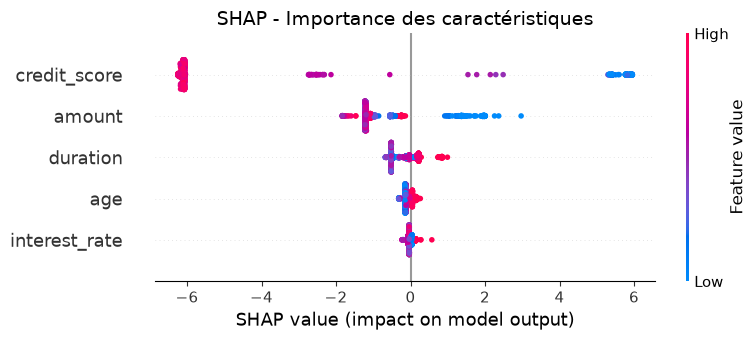

✅ Graphique SHAP affiché !


In [13]:
# Cellule 6 : SHAP Summary Plot (Version compatible)

import shap
import numpy as np

print("📊 Génération du graphique SHAP (Summary Plot)...")

# Préparer les données
data = df[model.features].copy()
for col in model.features:
    data[col] = data[col].fillna(data[col].mean())

data_scaled = model.scaler.transform(data)

# Calculer SHAP
shap_values = model.shap_explainer.shap_values(data_scaled)

# Afficher le summary plot (ancienne API, compatible)
shap.summary_plot(shap_values, data_scaled, feature_names=model.features, show=False)

# Ajouter un titre
plt.title("SHAP - Importance des caractéristiques", fontsize=14)
plt.tight_layout()
plt.show()

print("✅ Graphique SHAP affiché !")

💾 Image sauvegardée : docs/shap_summary.png


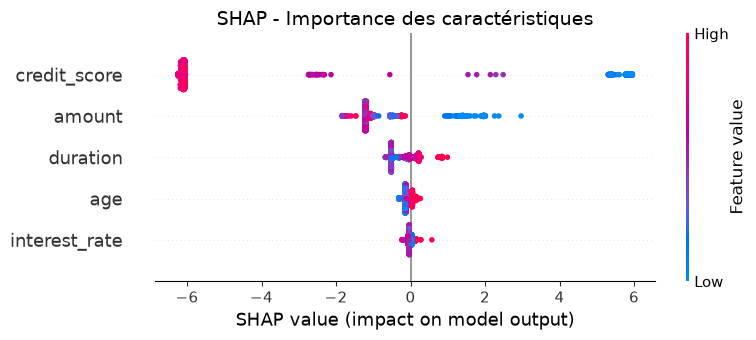

In [14]:
# Cellule 6b : Sauvegarder le Summary Plot
import shap

data = df[model.features].copy()
for col in model.features:
    data[col] = data[col].fillna(data[col].mean())

data_scaled = model.scaler.transform(data)
shap_values = model.shap_explainer.shap_values(data_scaled)

# Sauvegarder
shap.summary_plot(shap_values, data_scaled, feature_names=model.features, show=False)
plt.title("SHAP - Importance des caractéristiques", fontsize=14)
plt.tight_layout()
plt.savefig("../docs/shap_summary.png", dpi=300, bbox_inches='tight')
print("💾 Image sauvegardée : docs/shap_summary.png")
plt.show()

In [15]:
# Cellule 7 : Anomalies subtiles
print("🔎 Recherche d'anomalies subtiles...")

regle_metier = (df['amount'] < 0) | (df['credit_score'] < 300)
df_resultats = model.predict(df)
regle_ia = df_resultats['is_anomaly'] == True

anomalies_subtiles = df[ (~regle_metier) & regle_ia ]

print(f"✅ {len(anomalies_subtiles)} anomalies subtiles trouvées")
anomalies_subtiles.head(10)

🔎 Recherche d'anomalies subtiles...
✅ 45 anomalies subtiles trouvées


,amount,duration,interest_rate,age,credit_score,is_anomaly
1,44982.805483,191.245254,4.842645,73,310.304157,1.0
21,54846.846512,225.359210,4.910149,51,404.921485,1.0
26,9711.424883,4.334841,4.118791,24,439.800153,1.0
30,9556.736535,3.227920,4.303309,60,304.675369,1.0
50,49210.812451,163.924990,4.403348,86,401.151049,1.0
62,55033.032705,171.323884,4.790891,46,303.968538,1.0
80,49079.838004,189.696582,5.270221,57,370.016930,1.0
95,7698.528282,5.288653,4.392523,21,331.791247,1.0
106,49082.359139,230.016861,3.996066,43,357.201225,1.0
112,9856.340470,6.915988,4.073252,19,436.323256,1.0


In [16]:
# Cellule 8 : Sauvegarder les anomalies subtiles en CSV

import os

# 1. S'assurer que le dossier DataX existe
os.makedirs("../DataX", exist_ok=True)

# 2. Sauvegarder les anomalies subtiles
fichier_csv = "../DataX/anomalies_subtiles.csv"
anomalies_subtiles.to_csv(fichier_csv, index=False)

print(f"💾 {len(anomalies_subtiles)} anomalies sauvegardées dans : {fichier_csv}")

# 3. Afficher un aperçu du fichier
print("\n📋 Aperçu des anomalies sauvegardées :")
print(anomalies_subtiles.head())

💾 45 anomalies sauvegardées dans : ../DataX/anomalies_subtiles.csv

📋 Aperçu des anomalies sauvegardées :
          amount    duration  interest_rate  age  credit_score  is_anomaly
1   44982.805483  191.245254       4.842645   73    310.304157         1.0
21  54846.846512  225.359210       4.910149   51    404.921485         1.0
26   9711.424883    4.334841       4.118791   24    439.800153         1.0
30   9556.736535    3.227920       4.303309   60    304.675369         1.0
50  49210.812451  163.924990       4.403348   86    401.151049         1.0


In [17]:
# Cellule 9 : Statistiques des anomalies subtiles
print("📊 STATISTIQUES DES ANOMALIES SUBTILES")
print("=" * 40)

print(f"📌 Nombre total : {len(anomalies_subtiles)}")
print(f"\n📋 Moyennes :")
print(f"   - Amount : {anomalies_subtiles['amount'].mean():.2f} €")
print(f"   - Duration : {anomalies_subtiles['duration'].mean():.1f} mois")
print(f"   - Credit Score : {anomalies_subtiles['credit_score'].mean():.1f}")
print(f"   - Age : {anomalies_subtiles['age'].mean():.1f} ans")

📊 STATISTIQUES DES ANOMALIES SUBTILES
📌 Nombre total : 45

📋 Moyennes :
   - Amount : 32923.60 €
   - Duration : 115.1 mois
   - Credit Score : 378.9
   - Age : 58.8 ans


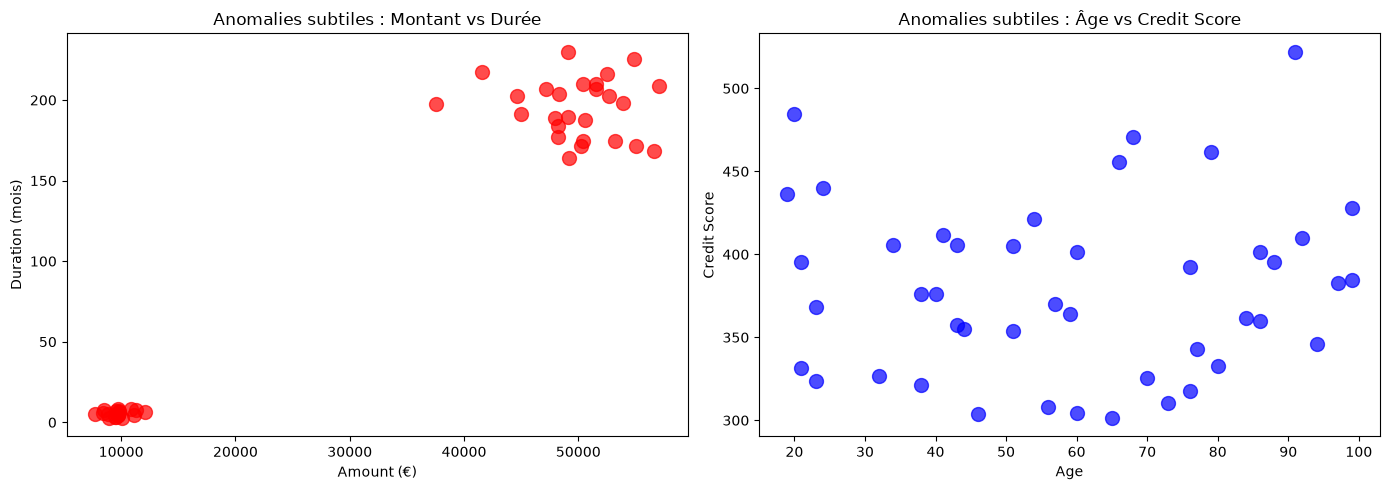

In [18]:
# Cellule 10 : Visualiser les anomalies subtiles
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Amount vs Duration
axes[0].scatter(anomalies_subtiles['amount'], anomalies_subtiles['duration'], 
                c='red', alpha=0.7, s=100)
axes[0].set_xlabel('Amount (€)')
axes[0].set_ylabel('Duration (mois)')
axes[0].set_title('Anomalies subtiles : Montant vs Durée')

# Graphique 2 : Age vs Credit Score
axes[1].scatter(anomalies_subtiles['age'], anomalies_subtiles['credit_score'], 
                c='blue', alpha=0.7, s=100)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Credit Score')
axes[1].set_title('Anomalies subtiles : Âge vs Credit Score')

plt.tight_layout()
plt.show()

In [19]:
# Installation de seaborn
import sys
!{sys.executable} -m pip install seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


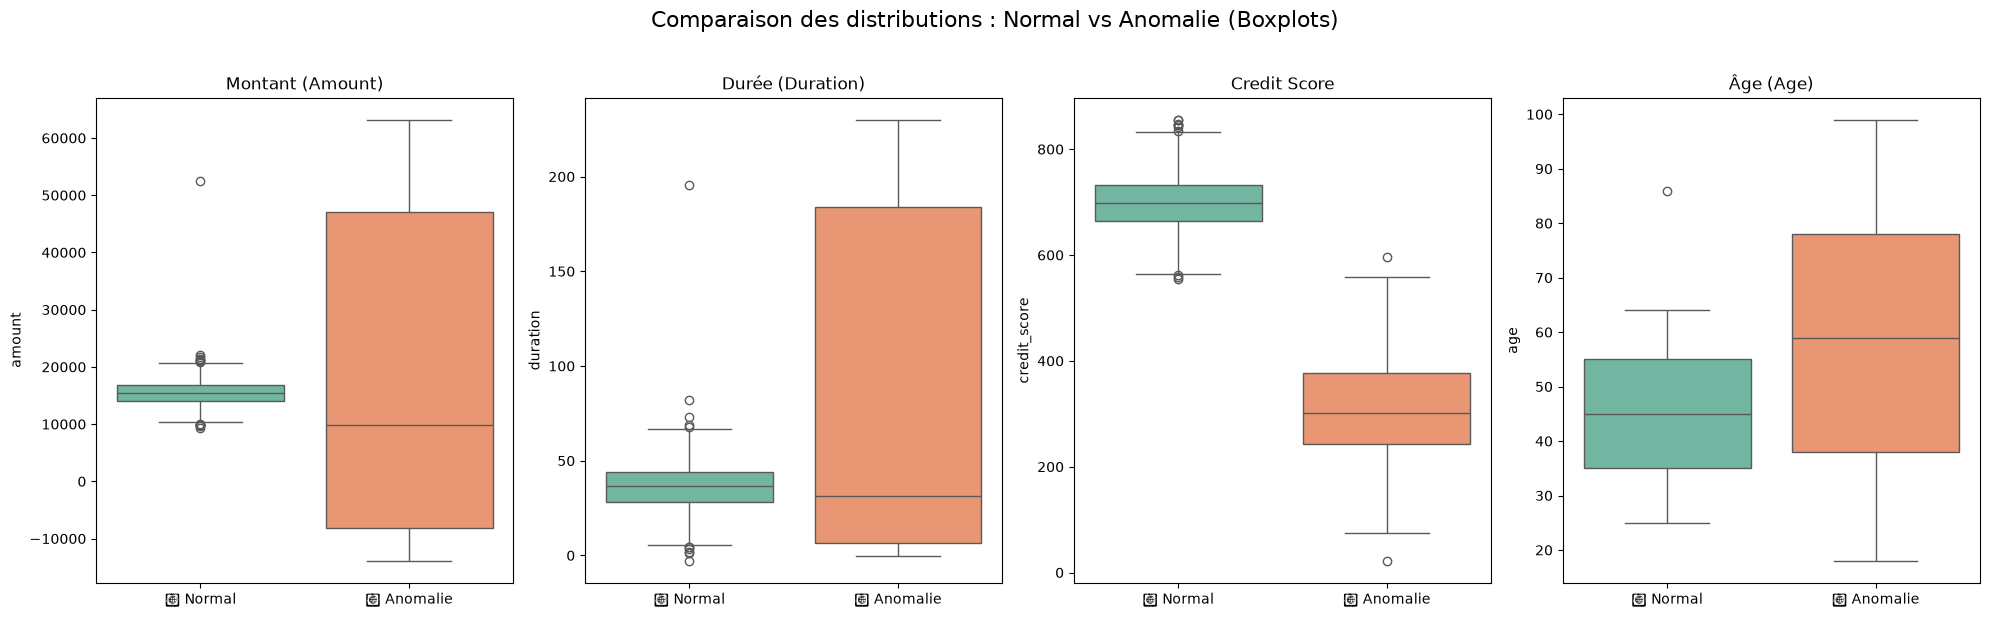

In [20]:
# Cellule 9 : Boxplot (Quantitative - Qualitative)
# Comparaison des distributions : Normal vs Anomalie

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Préparer les données
df_resultats = model.predict(df)
df_resultats['type'] = df_resultats['is_anomaly'].map({True: '🔴 Anomalie', False: '🔵 Normal'})

# 2. Créer les 4 graphiques côte à côte
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

# 3. Tracer les boxplots
sns.boxplot(x='type', y='amount', data=df_resultats, ax=axes[0], palette='Set2')
axes[0].set_title('Montant (Amount)', fontsize=12)
axes[0].set_xlabel('')

sns.boxplot(x='type', y='duration', data=df_resultats, ax=axes[1], palette='Set2')
axes[1].set_title('Durée (Duration)', fontsize=12)
axes[1].set_xlabel('')

sns.boxplot(x='type', y='credit_score', data=df_resultats, ax=axes[2], palette='Set2')
axes[2].set_title('Credit Score', fontsize=12)
axes[2].set_xlabel('')

sns.boxplot(x='type', y='age', data=df_resultats, ax=axes[3], palette='Set2')
axes[3].set_title('Âge (Age)', fontsize=12)
axes[3].set_xlabel('')

# 4. Afficher
plt.suptitle('Comparaison des distributions : Normal vs Anomalie (Boxplots)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [21]:
# Cellule 10 : Sauvegarder les boxplots
fig.savefig("../docs/boxplots_normal_vs_anomalies.png", dpi=300, bbox_inches='tight')
print("💾 Image sauvegardée dans : docs/boxplots_normal_vs_anomalies.png")


💾 Image sauvegardée dans : docs/boxplots_normal_vs_anomalies.png


In [5]:
# Créer le dossier models si nécessaire
import os
os.makedirs("../models", exist_ok=True)
print("✅ Dossier models/ créé")

✅ Dossier models/ créé


In [10]:
# Cellule 10 : Consolidation XGBoost + SHAP

print("=" * 60)
print("📊 CONSOLIDATION XGBoost + SHAP")
print("=" * 60)

# 1. Résumé du modèle
print("\n🔍 Résumé du modèle XGBoost :")
print(f"   - Features utilisées : {model.features}")
print(f"   - Précision : {model.metrics['accuracy']:.2%}")
print(f"   - F1-Score : {model.metrics['f1_score']:.2%}")
print(f"   - ROC AUC : {model.metrics['roc_auc']:.2%}")

# 2. Importance des caractéristiques
print("\n📊 Importance des caractéristiques :")
for feature, imp in sorted(model.get_importance().items(), key=lambda x: x[1], reverse=True):
    print(f"   - {feature} : {imp:.2%}")

# 3. Sauvegarder le modèle
import joblib
joblib.dump(model, "../models/xgboost_model.pkl")
print("\n💾 Modèle sauvegardé : models/xgboost_model.pkl")

📊 CONSOLIDATION XGBoost + SHAP

🔍 Résumé du modèle XGBoost :
   - Features utilisées : ['amount', 'duration', 'interest_rate', 'age', 'credit_score']
   - Précision : 99.67%
   - F1-Score : 0.00%
   - ROC AUC : 99.90%

📊 Importance des caractéristiques :
   - credit_score : 68.48%
   - amount : 15.30%
   - duration : 11.06%
   - interest_rate : 4.16%
   - age : 1.00%

💾 Modèle sauvegardé : models/xgboost_model.pkl


⚡ GÉNÉRATION AUTOMATIQUE DE RÈGLES

📊 Données analysées :
   - Total : 1500 lignes
   - Anomalies détectées : 149
   - Données normales : 1351

📋 RÈGLES PROPOSÉES PAR L'IA

1. duration > -9
   → valeur trop élevée (moyenne anomalies: 77)
   → Moyenne normale : 37 | Moyenne anomalies : 77
   → Écart : 40

2. interest_rate > 1
   → valeur trop élevée (moyenne anomalies: 11)
   → Moyenne normale : 4 | Moyenne anomalies : 11
   → Écart : 7

3. credit_score < 408
   → valeur trop basse (moyenne anomalies: 305)
   → Moyenne normale : 699 | Moyenne anomalies : 305
   → Écart : -393

💾 Règles sauvegardées : DataX/regles_proposees_ia.csv

📝 FORMAT SQL (INTÉGRABLE DANS LE RÉFÉRENTIEL)

-- Règle générée automatiquement #1
INSERT INTO Regles (REGLE_ID, NOM_REGLE, DESCRIPTION, EXPRESSION_SQL)
VALUES (
    'AUTO_DURATION',
    'Auto_DURATION_check',
    'Détection automatique : DURATION > -9',
    'SELECT * FROM CONTRACT WHERE DURATION > -9'
);

-- Règle générée automatiquement #2
INSERT INTO Regles

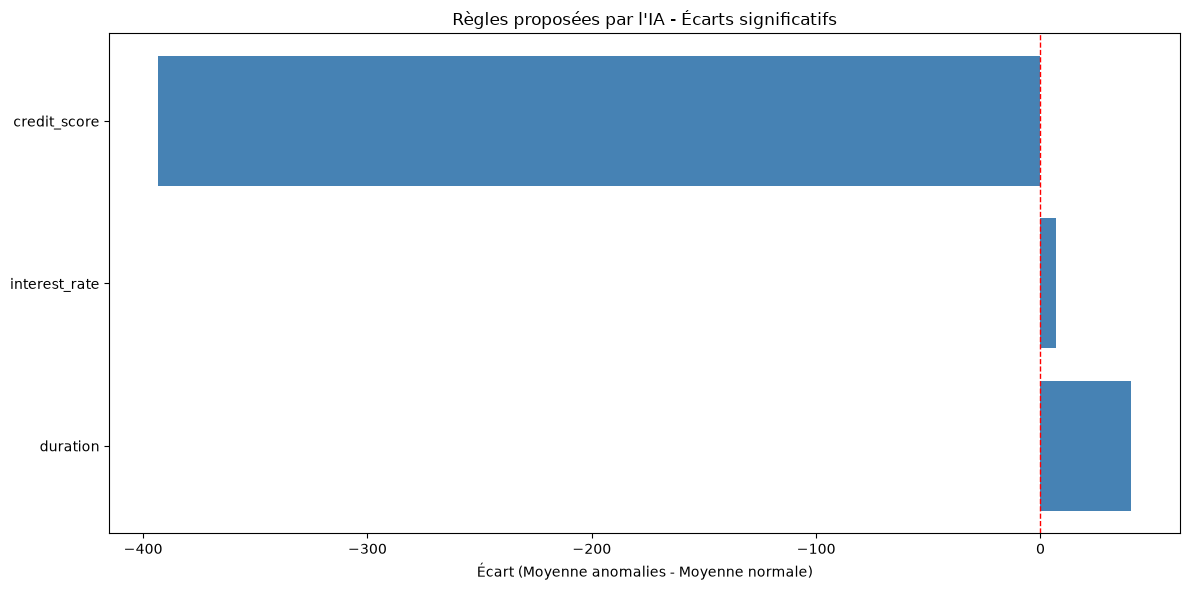

In [11]:
# Cellule 11 : Génération automatique de règles

print("=" * 60)
print("⚡ GÉNÉRATION AUTOMATIQUE DE RÈGLES")
print("=" * 60)

# 1. Récupérer les anomalies détectées par XGBoost
df_resultats = model.predict(df)
anomalies = df[df_resultats['is_anomaly'] == True]
normales = df[df_resultats['is_anomaly'] == False]

print(f"\n📊 Données analysées :")
print(f"   - Total : {len(df)} lignes")
print(f"   - Anomalies détectées : {len(anomalies)}")
print(f"   - Données normales : {len(normales)}")

if len(anomalies) == 0:
    print("\n⚠️ Aucune anomalie trouvée, impossible de générer des règles")
else:
    # 2. Analyser chaque colonne pour proposer des règles
    regles_proposees = []
    
    for col in model.features:
        # Statistiques des anomalies
        mean_anom = anomalies[col].mean()
        std_anom = anomalies[col].std()
        min_anom = anomalies[col].min()
        max_anom = anomalies[col].max()
        
        # Statistiques des données normales
        mean_norm = normales[col].mean()
        std_norm = normales[col].std()
        min_norm = normales[col].min()
        max_norm = normales[col].max()
        
        # Seuil pour considérer un écart comme significatif
        ecart = abs(mean_anom - mean_norm)
        seuil_significatif = std_norm * 1.5
        
        if ecart > seuil_significatif:
            # Déterminer la direction
            if mean_anom > mean_norm:
                direction = "élevée"
                seuil = mean_anom - std_anom
                operateur = ">"
                description = f"valeur trop élevée (moyenne anomalies: {mean_anom:.0f})"
            else:
                direction = "basse"
                seuil = mean_anom + std_anom
                operateur = "<"
                description = f"valeur trop basse (moyenne anomalies: {mean_anom:.0f})"
            
            regles_proposees.append({
                'colonne': col,
                'type': 'numerique',
                'operateur': operateur,
                'seuil': seuil,
                'direction': direction,
                'description': description,
                'mean_anom': mean_anom,
                'mean_norm': mean_norm,
                'std_anom': std_anom,
                'std_norm': std_norm
            })
    
    # 3. Afficher les règles proposées
    print("\n" + "=" * 60)
    print("📋 RÈGLES PROPOSÉES PAR L'IA")
    print("=" * 60)
    
    if len(regles_proposees) == 0:
        print("\n⚠️ Aucune règle significative trouvée")
    else:
        for i, regle in enumerate(regles_proposees, 1):
            print(f"\n{i}. {regle['colonne']} {regle['operateur']} {regle['seuil']:.0f}")
            print(f"   → {regle['description']}")
            print(f"   → Moyenne normale : {regle['mean_norm']:.0f} | Moyenne anomalies : {regle['mean_anom']:.0f}")
            print(f"   → Écart : {(regle['mean_anom'] - regle['mean_norm']):.0f}")
    
    # 4. Sauvegarder les règles en CSV
    import os
    os.makedirs("../DataX", exist_ok=True)
    df_regles_proposees = pd.DataFrame(regles_proposees)
    df_regles_proposees.to_csv("../DataX/regles_proposees_ia.csv", index=False)
    print(f"\n💾 Règles sauvegardées : DataX/regles_proposees_ia.csv")
    
    # 5. Générer le format SQL
    print("\n" + "=" * 60)
    print("📝 FORMAT SQL (INTÉGRABLE DANS LE RÉFÉRENTIEL)")
    print("=" * 60)
    
    for i, regle in enumerate(regles_proposees, 1):
        col = regle['colonne'].upper()
        seuil = regle['seuil']
        operateur = regle['operateur']
        
        print(f"\n-- Règle générée automatiquement #{i}")
        print(f"INSERT INTO Regles (REGLE_ID, NOM_REGLE, DESCRIPTION, EXPRESSION_SQL)")
        print(f"VALUES (")
        print(f"    'AUTO_{col}',")
        print(f"    'Auto_{col}_check',")
        print(f"    'Détection automatique : {col} {operateur} {seuil:.0f}',")
        print(f"    'SELECT * FROM CONTRACT WHERE {col} {operateur} {seuil:.0f}'")
        print(f");")
    
    print("\n" + "=" * 60)
    print("💡 UTILISATION DES RÈGLES")
    print("=" * 60)
    print("""
    1. Les règles sont sauvegardées dans DataX/regles_proposees_ia.csv
    2. Elles peuvent être intégrées au référentiel Excel
    3. Le moteur de validation pourra les exécuter automatiquement
    
    🔍 Exemple d'utilisation :
    - Une anomalie est détectée sur la colonne 'credit_score'
    - L'IA propose : "credit_score < 350"
    - Cette règle est ajoutée au référentiel
    - Le moteur de validation l'exécute sur les nouvelles données
    """)
    
    # 6. Bonus : Visualiser les règles
    print("\n📊 Visualisation rapide des règles :")
    plt.figure(figsize=(12, 6))
    
    cols = [r['colonne'] for r in regles_proposees]
    ecarts = [r['mean_anom'] - r['mean_norm'] for r in regles_proposees]
    
    plt.barh(cols, ecarts, color='steelblue')
    plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
    plt.xlabel('Écart (Moyenne anomalies - Moyenne normale)')
    plt.title('Règles proposées par l\'IA - Écarts significatifs')
    plt.tight_layout()
    plt.show()

In [7]:
# Cellule 12 : Test du modèle sur des cas d'anomalies

print("=" * 60)
print("🧪 TEST DU MODÈLE SUR DES CAS D'ANOMALIES")
print("=" * 60)

# 1. Créer 10 cas d'anomalies artificielles
cas_anomalies = pd.DataFrame({
    'amount': [50000, -5000, 60000, 45000, 70000, 3000, 55000, 65000, -2000, 48000],
    'duration': [200, 36, 250, 180, 300, 3, 220, 270, 36, 190],
    'interest_rate': [4.5, 4.5, 4.5, 4.5, 4.5, 4.5, 4.5, 4.5, 4.5, 4.5],
    'age': [50, 50, 50, 50, 50, 50, 50, 50, 50, 50],
    'credit_score': [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
})

# 2. Ajouter quelques cas normaux
cas_normaux = pd.DataFrame({
    'amount': [12000, 15000, 18000, 20000, 25000],
    'duration': [36, 48, 60, 72, 84],
    'interest_rate': [4.5, 4.5, 4.5, 4.5, 4.5],
    'age': [40, 45, 50, 55, 60],
    'credit_score': [700, 720, 750, 780, 800]
})

# 3. Combiner
cas_test = pd.concat([cas_anomalies, cas_normaux], ignore_index=True)

# 4. Prédire
resultats_test = model.predict(cas_test)

# 5. Afficher les résultats
print("\n📋 RÉSULTATS DES PRÉDICTIONS :")
print("-" * 60)

for i, row in cas_test.iterrows():
    is_anomaly = resultats_test['is_anomaly'].iloc[i]
    proba = resultats_test['probability'].iloc[i]
    statut = "🔴 ANOMALIE" if is_anomaly else "🟢 NORMAL"
    
    print(f"{statut} - Probabilité : {proba:.2%}")
    print(f"   Amount: {row['amount']:.0f}€ | Durée: {row['duration']} mois | Score: {row['credit_score']}")
    print()

# 6. Calculer les métriques sur ce test
y_true = [1] * len(cas_anomalies) + [0] * len(cas_normaux)
y_pred = resultats_test['is_anomaly'].astype(int).tolist()

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

print("=" * 60)
print("📊 MÉTRIQUES SUR LE TEST AVEC ANOMALIES")
print("=" * 60)
print(f"   Précision : {precision_score(y_true, y_pred):.2%}")
print(f"   Rappel : {recall_score(y_true, y_pred):.2%}")
print(f"   F1-Score : {f1_score(y_true, y_pred):.2%}")
print(f"   Accuracy : {accuracy_score(y_true, y_pred):.2%}")

🧪 TEST DU MODÈLE SUR DES CAS D'ANOMALIES

📋 RÉSULTATS DES PRÉDICTIONS :
------------------------------------------------------------
🔴 ANOMALIE - Probabilité : 99.86%
   Amount: 50000€ | Durée: 200.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.94%
   Amount: -5000€ | Durée: 36.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.86%
   Amount: 60000€ | Durée: 250.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.84%
   Amount: 45000€ | Durée: 180.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.86%
   Amount: 70000€ | Durée: 300.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.94%
   Amount: 3000€ | Durée: 3.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.86%
   Amount: 55000€ | Durée: 220.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.86%
   Amount: 65000€ | Durée: 270.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.94%
   Amount: -2000€ | Durée: 36.0 mois | Score: 300.0

🔴 ANOMALIE - Probabilité : 99.85%
   Amount: 48000€ | Durée: 190.0 mois | Score: